# 04.01 — Solución fundamental de la ecuación del calor

## 04.01.0 — Orden de esta colección

Este es el **Notebook 01** de la secuencia de las notas.

Su correspondencia con el temario oficial es

$$
\boxed{\text{Tema oficial 4.1: solución fundamental}}
$$

La fuente principal es la página 1 de `Calor.pdf`.

Todas las fórmulas de este notebook usan delimitadores compatibles con Jupyter:

$$
\texttt{\$\$ \cdots \$\$}
$$

Las ecuaciones están escritas con la sintaxis estándar de MathJax para Jupyter.


## 04.01.1 — Transcripción literal normalizada de las notas

### **Proposición 04.01.1 — Solución fundamental**

En las notas aparece

$$
\psi(x,t)
=
\begin{cases}
\dfrac{1}{(4\pi t)^{n/2}}
\exp\!\left(-\dfrac{|x|^2}{4t}\right),
&
x\in\mathbb R^n,\quad t>0,
\\[3mm]
0,
&
x\in\mathbb R^n,\quad t\leq 0.
\end{cases}
$$

y se afirma que

$$
\psi
$$

es la solución fundamental de la ecuación del calor.


## 04.01.2 — Simulación estática

La siguiente celda dibuja la familia

$$
\psi(x,t)
=
\frac{1}{\sqrt{4\pi t}}
\exp\!\left(-\frac{x^2}{4t}\right)
$$

en dimensión uno.

La masa exacta es

$$
\int_{\mathbb R}\psi(x,t)\,dx=1,
$$

la altura máxima es

$$
\psi(0,t)=\frac{1}{\sqrt{4\pi t}},
$$

y el segundo momento es

$$
\int_{\mathbb R}x^2\psi(x,t)\,dx=2t.
$$


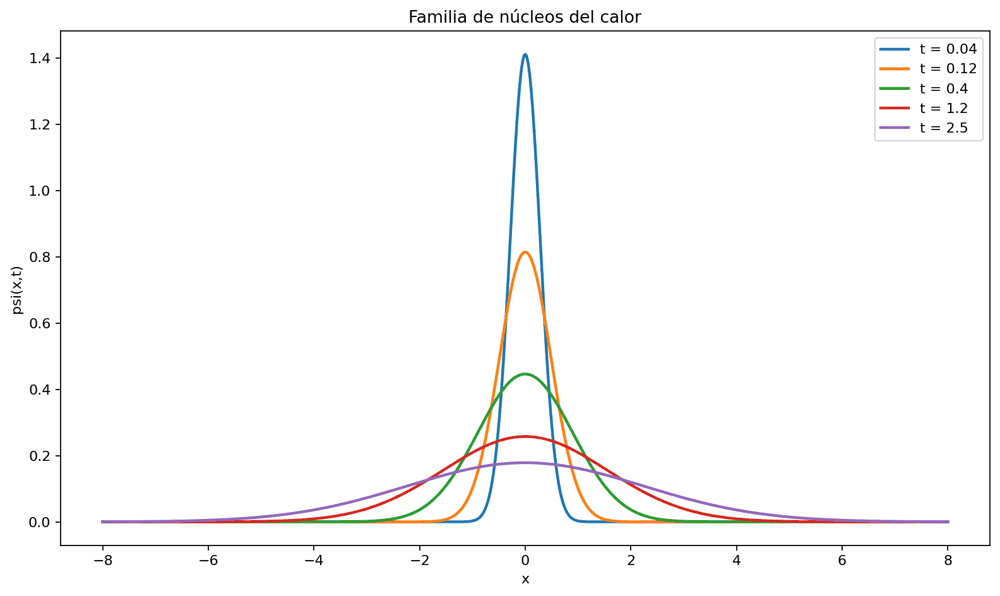

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-8.0, 8.0, 2400)
times = [0.04, 0.12, 0.40, 1.20, 2.50]

def psi(x, t):
    return np.exp(-(x**2) / (4.0 * t)) / np.sqrt(4.0 * np.pi * t)

plt.figure(figsize=(10, 6), dpi=160)

for t in times:
    plt.plot(x, psi(x, t), linewidth=2, label=f"t = {t}")

plt.xlabel("x")
plt.ylabel("psi(x,t)")
plt.title("Familia de núcleos del calor")
plt.legend()
plt.tight_layout()
plt.show()


## 04.01.3 — Formulación clásica

### **Definición 04.01.2 — Operador del calor**

Sea

$$
n\geq 1.
$$

El operador

$$
H=\partial_t-\Delta
$$

se denomina **operador del calor**.

---

### **Definición 04.01.3 — Solución fundamental hacia adelante**

Una distribución

$$
\psi\in\mathcal D'(\mathbb R^n\times\mathbb R)
$$

es una **solución fundamental hacia adelante** de

$$
H=\partial_t-\Delta
$$

si

$$
H\psi=\delta_{(0,0)}
$$

en el sentido de distribuciones y

$$
\operatorname{supp}\psi
\subseteq
\mathbb R^n\times[0,\infty).
$$


## 04.01.4 — Verificación del núcleo

### **Teorema 04.01.4 — Núcleo de Gauss**

Para

$$
t>0,
$$

la función

$$
\psi(x,t)
=
\frac{1}{(4\pi t)^{n/2}}
\exp\!\left(-\frac{|x|^2}{4t}\right)
$$

satisface

$$
\psi_t-\Delta\psi=0
$$

en

$$
\mathbb R^n\times(0,\infty),
$$

es positiva y tiene masa uno.

### Demostración

Se calcula

$$
\psi_t
=
\left(
-\frac{n}{2t}
+
\frac{|x|^2}{4t^2}
\right)\psi.
$$

Para cada índice

$$
i\in\{1,\ldots,n\},
$$

se tiene

$$
\psi_{x_i}
=
-\frac{x_i}{2t}\psi
$$

y

$$
\psi_{x_i x_i}
=
\left(
-\frac{1}{2t}
+
\frac{x_i^2}{4t^2}
\right)\psi.
$$

Al sumar,

$$
\Delta\psi
=
\left(
-\frac{n}{2t}
+
\frac{|x|^2}{4t^2}
\right)\psi
=
\psi_t.
$$

Para la masa hacemos el cambio de variables

$$
x=\sqrt{4t}\,z.
$$

Entonces

$$
\int_{\mathbb R^n}\psi(x,t)\,dx
=
\frac{1}{\pi^{n/2}}
\int_{\mathbb R^n}e^{-|z|^2}\,dz
=
1.
$$

Esto prueba el resultado.


## 04.01.5 — Aproximación de la identidad

### **Teorema 04.01.5 — Convergencia al dato inicial**

Sea

$$
g\in C_b(\mathbb R^n).
$$

Si

$$
g
$$

es continua en

$$
x_0\in\mathbb R^n,
$$

entonces

$$
\lim_{t\downarrow 0}
\int_{\mathbb R^n}
\psi(x_0-y,t)g(y)\,dy
=
g(x_0).
$$

Por tanto,

$$
\psi(\cdot,t)\longrightarrow\delta_0
$$

en el sentido de distribuciones.

---

### **Corolario 04.01.6 — Fórmula de Gauss**

Bajo las hipótesis anteriores,

$$
u(x,t)
=
\int_{\mathbb R^n}
\psi(x-y,t)g(y)\,dy
$$

satisface

$$
u_t-\Delta u=0
$$

para

$$
t>0
$$

y recupera el dato inicial cuando

$$
t\downarrow0.
$$


## 04.01.6 — Animación Manim

Ejecuta la gráfica estática y después la siguiente celda para renderizar y reproducir el MP4 en este cuaderno.

In [ ]:
from pathlib import Path
from runpy import run_path

carpeta = Path.cwd()
if (carpeta / "calor").is_dir():
    carpeta = carpeta / "calor"
renderizar = run_path(str(carpeta / "manim" / "perfiles.py"))["renderizar_perfiles"]

def perfiles(t):
    return [(x, psi(x, t))]

renderizar("Núcleo del calor", perfiles, (0.04, 2.5), [-8,8,2], [0,1.5,0.25],
           ["Densidad de masa unitaria"])


## 04.01.7 — Ejercicios de práctica

### **Ejercicio 04.01.1**

Demuestre que

$$
\int_{\mathbb R^n}x_i\psi(x,t)\,dx=0
$$

para cada índice

$$
i.
$$

### **Ejercicio 04.01.2**

Demuestre que

$$
\int_{\mathbb R^n}|x|^2\psi(x,t)\,dx=2nt.
$$



## 04.01.8 — Avance

Se cubrió

$$
\boxed{\text{solución fundamental y fórmula de Gauss}}
$$

del tema oficial

$$
4.1.
$$

El siguiente notebook, siguiendo el orden de las notas, es

$$
\boxed{\text{04.02 — Soluciones de Tychonoff}}.
$$
